# Quickstart: counterfactual rules of a heart-disease classifier

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ClaudioDaka99/RaMiCo/blob/main/examples/01_quickstart.ipynb)

A classifier predicts heart disease from 13 clinical measurements. Which change to a patient's measurements would
change its diagnosis, and how consistently across patients? **RaMiCo** answers with *global counterfactual rules*:
for every pair of classes, the single-feature switches that move the model from one class to the other, summarised
over many patients.

**In this notebook you will**

1. train the black box, the XGBoost or the MLP pipeline of the RaMiCo paper;
2. extract its counterfactual rules with one call;
3. read a rule: the switched feature, its values before and after the switch, the arrival class, how often the rule
   occurs and how realistic its switches are;
4. see all the rules at once as a graph, and thin it out by support and by size of the change;
5. score the rules with the three metrics of the paper: fidelity, incomprehensibility and implausibility;
6. save the rules and their scores to a file, and load them back without fitting again.

| | |
|---|---|
| **Prerequisites** | Python ≥ 3.11, `pip install "ramico[tutorials]"`, basic scikit-learn |
| **Duration** | about 1 minute; 15 seconds with `QUICK = True` |
| **Hardware** | any laptop, no GPU needed |

In [1]:
# On Colab, install RaMiCo and the libraries of the tutorials first
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "ramico[tutorials]"

In [2]:
QUICK = False  # True: fewer factuals and counterfactuals, same tables and figures
SEED = 42
MODEL = "xgboost"  # black box of the paper: "xgboost" or "mlp"
N_SEEDS = 30  # used by the benchmark tutorials; one run is enough here
DEVICE = "auto"  # XGBoost device: "auto", "cpu" or "cuda"

In [3]:
import pandas as pd
from great_tables import GT
from sklearn.compose import make_column_transformer
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

import ramico
from ramico import RaMiCo, datasets, metrics, viz

if MODEL not in ("xgboost", "mlp"):
    raise ValueError(f'MODEL must be "xgboost" or "mlp", not {MODEL!r}')
viz.theme.apply()  # one visual theme for every table and figure
N_FACTUALS, N_COUNTERFACTUALS = (25, 10) if QUICK else (100, 50)  # s and k in the paper
XGB_DEVICE = "cpu" if DEVICE == "auto" else DEVICE  # 300 patients: a GPU would not be faster
print(f"ramico {ramico.__version__} · {N_FACTUALS} factuals and {N_COUNTERFACTUALS} counterfactuals per class")

ramico 0.1.0 · 100 factuals and 50 counterfactuals per class


## 1. The patients

The Cleveland Heart Disease data of the UCI repository: 297 patients with complete records, 13 clinical features and
the diagnosis, here reduced to *disease* or *no disease*. `ramico.datasets` downloads the file once, checks its
SHA-256 checksum and keeps it in a local cache.

In [4]:
data = datasets.load_heart_disease()
X, y = data

MEANING = {
    "age": "age (years)",
    "sex": "sex",
    "cp": "chest pain type",
    "trestbps": "resting blood pressure (mm Hg)",
    "chol": "serum cholesterol (mg/dl)",
    "fbs": "fasting blood sugar > 120 mg/dl",
    "restecg": "resting electrocardiogram",
    "thalach": "maximum heart rate achieved (bpm)",
    "exang": "angina induced by exercise",
    "oldpeak": "ST depression induced by exercise (mm)",
    "slope": "slope of the peak exercise ST segment",
    "ca": "major vessels coloured by fluoroscopy",
    "thal": "thallium stress test",
}
categorical = data.categorical_features
overview = pd.DataFrame(
    {
        "feature": X.columns,
        "meaning": [MEANING[c] for c in X.columns],
        "kind": ["categorical" if c in categorical else "numerical" for c in X.columns],
        "values": [
            " · ".join(X[c].cat.categories) if c in categorical else f"{X[c].min():g} to {X[c].max():g}"
            for c in X.columns
        ],
    }
)
(
    GT(overview, rowname_col="feature")
    .tab_header("Heart Disease (Cleveland)", f"{len(X)} patients · {y.mean():.0%} with heart disease")
    .cols_label(meaning="Meaning", kind="Kind", values="Range or categories")
    .tab_source_note(
        "Source: UCI Machine Learning Repository, processed.cleveland.data; rows with missing values dropped."
    )
)

GT(_tbl_data=     feature                                 meaning         kind  \
0        age                             age (years)    numerical   
1        sex                                     sex  categorical   
2         cp                         chest pain type  categorical   
3   trestbps          resting blood pressure (mm Hg)    numerical   
4       chol               serum cholesterol (mg/dl)    numerical   
5        fbs         fasting blood sugar > 120 mg/dl  categorical   
6    restecg               resting electrocardiogram  categorical   
7    thalach       maximum heart rate achieved (bpm)    numerical   
8      exang              angina induced by exercise  categorical   
9    oldpeak  ST depression induced by exercise (mm)    numerical   
10     slope   slope of the peak exercise ST segment  categorical   
11        ca   major vessels coloured by fluoroscopy    numerical   
12      thal                    thallium stress test  categorical   

                                               values  
0                                            29 to 77  
1                                       female · male  
2   typical angina · atypical angina · non-anginal...  
3                                           94 to 200  
4                                          126 to 564  
5                                            no · yes  
6          normal · ST-T abnormality · LV hypertrophy  
7                                           71 to 202  
8                                            no · yes  
9                                            0 to 6.2  
10                     upsloping · flat · downsloping  
11                                             0 to 3  
12          normal · fixed defect · reversible defect  , _body=<great_tables._gt_data.Body object at 0x000002AF7D9D58B0>, _boxhead=Boxhead([ColInfo(var='feature', type=<ColInfoTypeEnum.stub: 2>, column_label='feature', column_align='left', column_width=None, stub_level=0), ColInfo(var='meaning', type=<ColInfoTypeEnum.default: 1>, column_label='Meaning', column_align='left', column_width=None, stub_level=None), ColInfo(var='kind', type=<ColInfoTypeEnum.default: 1>, column_label='Kind', column_align='left', column_width=None, stub_level=None), ColInfo(var='values', type=<ColInfoTypeEnum.default: 1>, column_label='Range or categories', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000002AF7D9AB9B0>, _spanners=Spanners([]), _heading=Heading(title='Heart Disease (Cleveland)', subtitle='297 patients · 46% with heart disease', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000002AF7D9D5A30>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000002AF7D9D5880>, _source_notes=['Source: UCI Machine Learning Repository, processed.cleveland.data; rows with missing values dropped.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000002AF7D9D5160>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Aria

## 2. The black box

RaMiCo is model-agnostic: it only calls `predict`. As in the paper, the black box works behind one-hot encoding of
the categorical features and standardisation of the numerical ones, and is trained on 80% of the patients. `MODEL`, in
the first code cell, chooses which of the paper's two black boxes:

- `"xgboost"`: an XGBoost classifier with the hyperparameters of the paper for this dataset, the run shown here;
- `"mlp"`: a multilayer perceptron with three hidden layers of 1024, 512 and 256 units, as in the paper's MLP
  experiments.

With the MLP the rules and the numbers change; the comments below describe the XGBoost run.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
numerical = [c for c in X.columns if c not in categorical]
encode = make_column_transformer((OneHotEncoder(handle_unknown="ignore"), categorical), (StandardScaler(), numerical))
if MODEL == "mlp":
    classifier = MLPClassifier(  # the MLP of the paper's experiments on Heart Disease
        hidden_layer_sizes=(1024, 512, 256),
        alpha=0.001,
        batch_size=128,
        learning_rate_init=0.0005,
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=SEED,
    )
else:
    classifier = XGBClassifier(  # hyperparameters of the paper for this dataset
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=0.3,
        min_child_weight=5,
        reg_alpha=0.1,
        reg_lambda=2.0,
        eval_metric="logloss",
        tree_method="hist",
        device=XGB_DEVICE,
        random_state=SEED,
    )
model = make_pipeline(encode, classifier).fit(X_train, y_train)

predicted = model.predict(X_test)
print(
    f"Test accuracy {accuracy_score(y_test, predicted):.1%} · "
    f"balanced accuracy {balanced_accuracy_score(y_test, predicted):.1%} on {len(X_test)} patients"
)

Test accuracy 83.3% · balanced accuracy 82.8% on 60 patients


## 3. Extracting the rules

One call does it. For every class *c*, a **mining strategy** picks `n_factuals` patients of class *c* (the
factuals) and, for each of them, `n_counterfactuals` patients of the other class (the counterfactuals). RaMiCo then
switches **one feature at a time** from the factual's value to the counterfactual's: every switch that changes the
prediction becomes an elementary *record*, and records are aggregated into *rules* by starting class, arrival class
and feature.

The default strategy is the **ensemble** of the paper: prototype, nearest-boundary and random-pairs mining, each
keeping its own rules. Each switched patient also gets an *implausibility*, its anomaly score under an Isolation
Forest trained on the data, from 0 (typical) to 1 (most anomalous). `isolation_forest="native"` selects RaMiCo's own
implementation of the paper's forest, which gives the same scores at every run; YDF, used by default when
installed, varies slightly from run to run.

In [6]:
explainer = RaMiCo(
    model, n_factuals=N_FACTUALS, n_counterfactuals=N_COUNTERFACTUALS, random_state=SEED, isolation_forest="native"
)
rules = explainer.fit(X_train, y_train, class_names=data.target_names)
rules

feature,switch,support,implausibility,records,strategy
thal,reversible defect (95.7%) → normal (99.2%),4.85%,0.587,"1,067",prototype
cp,asymptomatic (89%) → non-anginal pain (74.5%),4.28%,0.607,942,prototype
thal,reversible defect (94.2%) → normal (97.3%),4.00%,0.598,880,random-pairs
cp,asymptomatic (87%) → non-anginal pain (69.6%),3.95%,0.641,868,random-pairs
thal,reversible defect (94.2%) → normal (95.8%),3.39%,0.577,746,nearest-boundary
ca,1.49 ± 0.69 → 0.00 ± 0.00,3.37%,0.533,741,nearest-boundary
cp,asymptomatic (87.5%) → non-anginal pain (64.6%),3.26%,0.627,717,nearest-boundary
ca,1.38 ± 0.60 → 0.00 ± 0.00,3.06%,0.509,672,prototype
ca,1.55 ± 0.73 → 0.00 ± 0.00,2.96%,0.563,651,random-pairs
slope,flat (100%) → upsloping (99.2%),1.73%,0.584,381,prototype


In a notebook a `RuleSet` displays itself: one table per class transition, rules sorted by **support** (the share
of all records that follow the rule, drawn as a bar), with their **implausibility** (deeper blue: less realistic
switches). When several strategies contribute, a dot marks the strategy that found each rule.

## 4. The rules at a glance

`rules.plot()` draws every rule at once, as a graph. Each band is a feature and each column a class: a rule is
an arrow from the value its patients start from, in the column of their class, to the value they are switched to.
Rules that share a value share its node; numerical values are rounded to about a twentieth of the range of the
feature, and hovering an arrow gives its exact values. Every arrow has the same width and the colour of the
mining strategy that found the rule: each of the three strategies of the ensemble draws its own arrow.
Hovering an arrow also gives its support and implausibility. Three sliders below the graph thin it out:
**Minimum support** keeps the strongest rules, **Largest change** the switches that move a numerical feature by
at most that share of its range (a categorical switch counts as a full change), **Largest implausibility** the
rules whose switched patients are realistic enough.

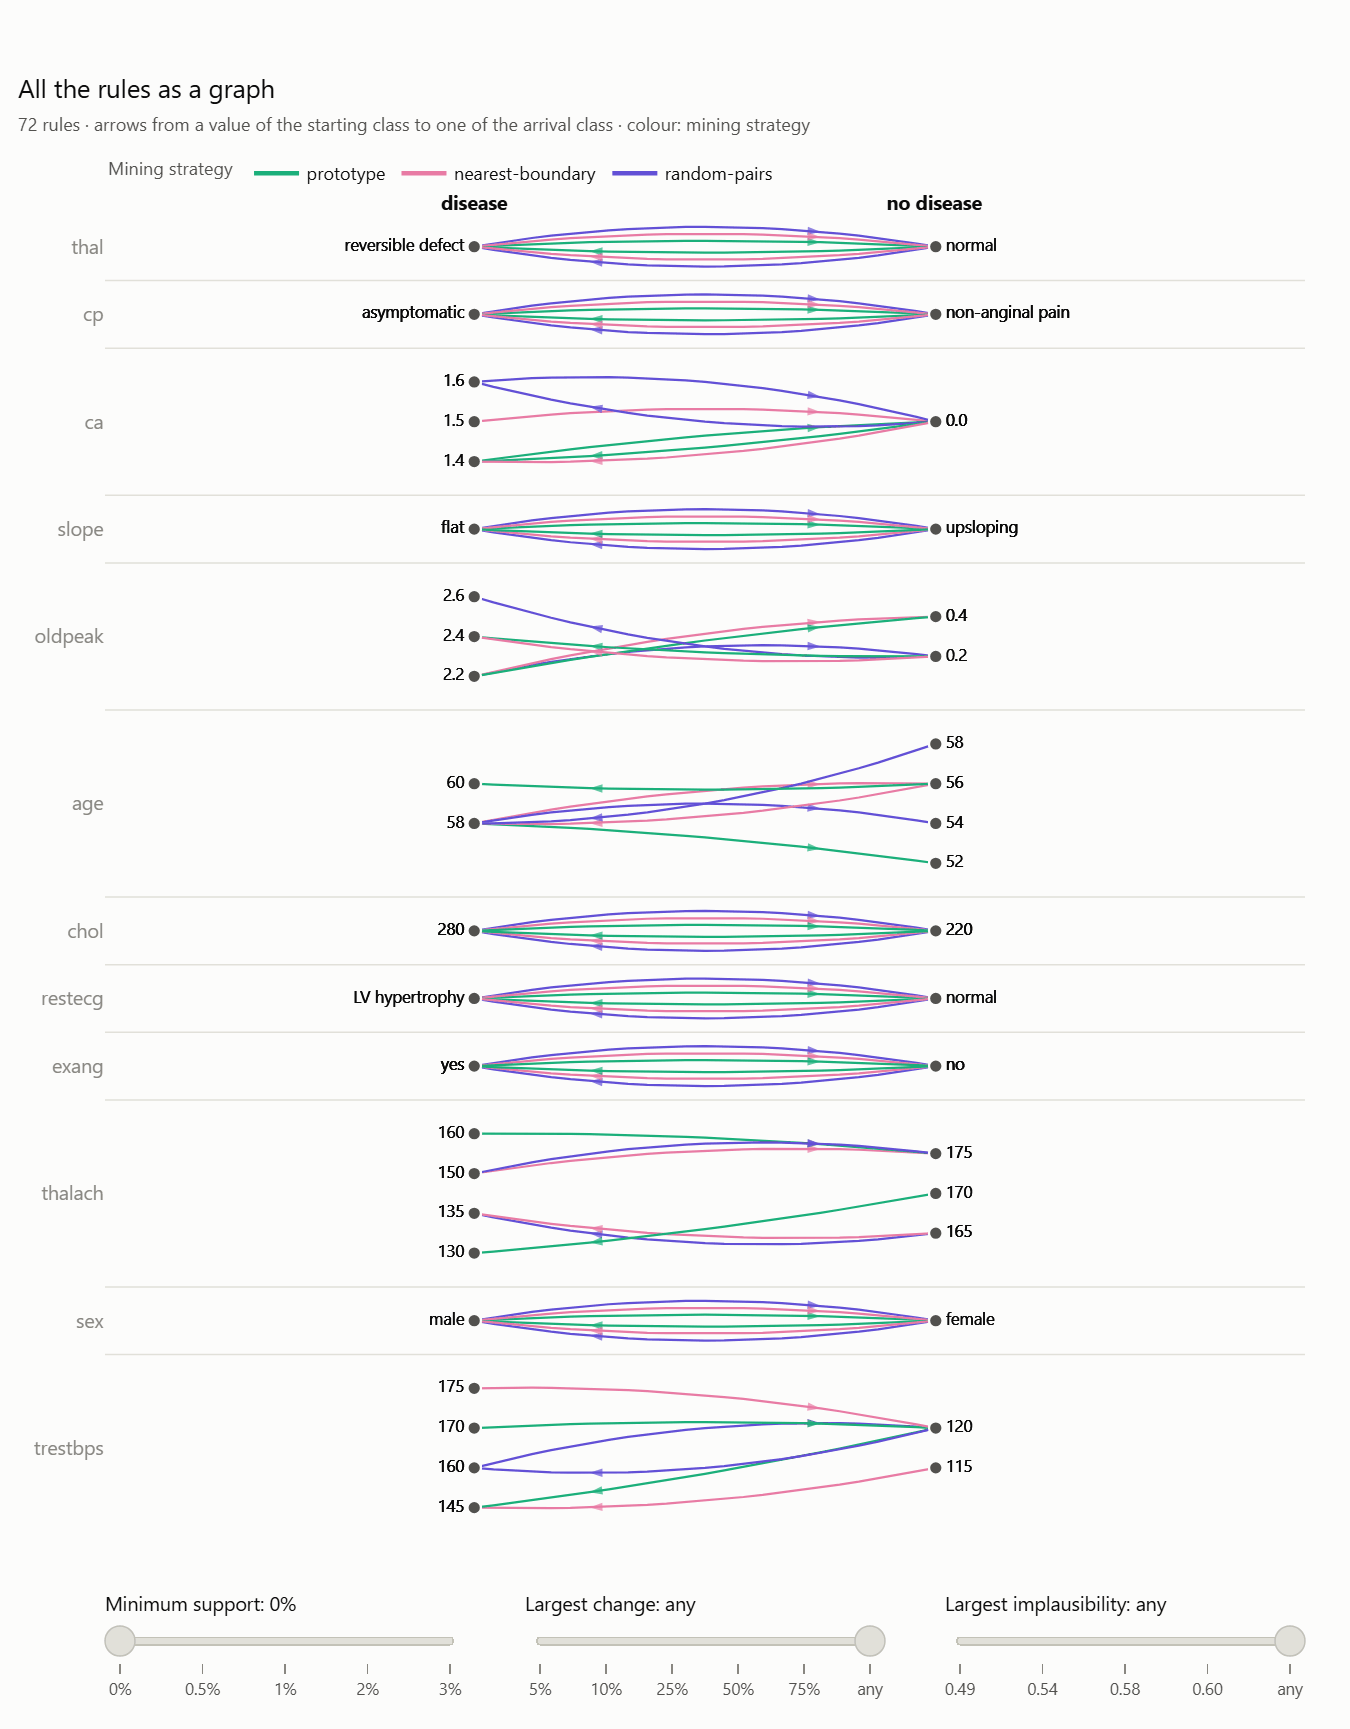

In [7]:
viz.show(rules.plot())

Arrows to *no disease* bend upwards, those back to *disease* downwards; the bands are sorted by their strongest
rule. The three top bands, thallium test, chest pain and vessels coloured by fluoroscopy, hold every
rule with a support of at least 2%, and in both directions the model moves between the same values: *reversible
defect* and *normal*, *asymptomatic* and *non-anginal pain*, about 1.5 vessels and none. Towards *no disease* the
numerical features converge: ST depression from about 2.2 to 0.3 mm, cholesterol from about 280 to 220 mg/dl,
blood pressure from 160–175 to 120 mm Hg, maximum heart rate from 150–160 up to about 175 bpm. With **Largest
change** at 25% only age, cholesterol, heart rate and blood pressure are left: the smallest single changes that
flip the model.

The sliders combine. With **Minimum support** at 2% and **Largest implausibility** at 0.54, four rules are left:
two strategies agree that no vessel coloured by fluoroscopy moves patients to *no disease*, and the chest pain and
thallium rules lead back to *disease*. These are the strong rules whose switched patients stay realistic.

## 5. Anatomy of a rule

Take the strongest rule that moves the model from *disease* to *no disease*:

In [8]:
rule = rules.filter(from_class=1, to_class=0)[0]
rule

Rule(strategy='prototype', from_class=1, to_class=0, feature='thal', aggregation='mode', from_value='reversible defect', from_std=nan, from_confidence=95.69, to_value='normal', to_std=nan, to_confidence=99.16, n_records=1067, support=4.85, implausibility=0.587, implausibility_std=0.163, from_name='disease', to_name='no disease')

Reading it field by field:

- **feature switched**: the only feature that changes; all the others keep the factual patient's values;
- **factual value**: the value held by the patients the rule starts from;
- **counterfactual value**: the value after the switch;
- **prediction**: the starting class and the class the model moves to;
- **support**: the share of all records that follow this rule, and their number;
- **implausibility**: the average anomaly score of the switched patients, with its standard deviation.

Categorical values are summarised by their most frequent value and its share of the records; numerical values by
mean ± standard deviation, so that the rule holds in an interval (see below).

Each record pairs a factual patient with one counterfactual patient, and counterfactuals that share the same value
give the same switched patient, so a factual usually contributes several identical records. Grouped by patient, the
switches with the lowest implausibility show whom the rule fits best:

In [9]:
behind = rules.records_of(rule)
switches = (
    behind.groupby(["factual_index", "from_value", "to_value"], as_index=False)
    .agg(records=("implausibility", "size"), implausibility=("implausibility", "mean"))
    .nsmallest(6, "implausibility")
)
patients = X_train.loc[switches["factual_index"], ["age", "sex", "cp"]].reset_index(drop=True)
(
    GT(pd.concat([switches.reset_index(drop=True), patients], axis=1))
    .tab_header(
        f"The most realistic switches of {rule.feature}",
        f"{len(behind)} records from {behind['factual_index'].nunique()} factual patients",
    )
    .cols_move_to_start(["factual_index", "age", "sex", "cp"])
    .tab_spanner("Factual patient", ["factual_index", "age", "sex", "cp"])
    .tab_spanner(f"Switch of {rule.feature}", ["from_value", "to_value"])
    .cols_label(factual_index="patient", cp="chest pain", from_value="before", to_value="after")
    .fmt_number("implausibility", decimals=3)
    .data_color("implausibility", palette=list(viz.theme.SEQUENTIAL[:7]), domain=[0, 1])
)

GT(_tbl_data=   factual_index         from_value to_value  records  implausibility  age  \
0            234  reversible defect   normal       46        0.299083   46   
1            178  reversible defect   normal       46        0.321835   48   
2            106  reversible defect   normal       46        0.381575   57   
3             56  reversible defect   normal       46        0.411602   50   
4            108  reversible defect   normal       46        0.411971   39   
5            245  reversible defect   normal       46        0.447122   52   

    sex                cp  
0  male      asymptomatic  
1  male      asymptomatic  
2  male  non-anginal pain  
3  male  non-anginal pain  
4  male      asymptomatic  
5  male      asymptomatic  , _body=<great_tables._gt_data.Body object at 0x000002AF0D512120>, _boxhead=Boxhead([ColInfo(var='factual_index', type=<ColInfoTypeEnum.default: 1>, column_label='patient', column_align='right', column_width=None, stub_level=None), ColInfo(var='age', type=<ColInfoTypeEnum.default: 1>, column_label='age', column_align='right', column_width=None, stub_level=None), ColInfo(var='sex', type=<ColInfoTypeEnum.default: 1>, column_label='sex', column_align='center', column_width=None, stub_level=None), ColInfo(var='cp', type=<ColInfoTypeEnum.default: 1>, column_label='chest pain', column_align='center', column_width=None, stub_level=None), ColInfo(var='from_value', type=<ColInfoTypeEnum.default: 1>, column_label='before', column_align='left', column_width=None, stub_level=None), ColInfo(var='to_value', type=<ColInfoTypeEnum.default: 1>, column_label='after', column_align='left', column_width=None, stub_level=None), ColInfo(var='records', type=<ColInfoTypeEnum.default: 1>, column_label='records', column_align='right', column_width=None, stub_level=None), ColInfo(var='implausibility', type=<ColInfoTypeEnum.default: 1>, column_label='implausibility', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000002AF0D99E420>, _spanners=Spanners([SpannerInfo(spanner_id='Factual patient', spanner_level=0, spanner_label='Factual patient', spanner_units=None, spanner_pattern=None, vars=['factual_index', 'age', 'sex', 'cp'], built=None), SpannerInfo(spanner_id='Switch of thal', spanner_level=0, spanner_label='Switch of thal', spanner_units=None, spanner_pattern=None, vars=['from_value', 'to_value'], built=None)]), _heading=Heading(title='The most realistic switches of thal', subtitle='1067 records from 23 factual patients', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000002AF0D9E9F40>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000002AF0D9E9610>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns='implausibility', rows=[0], mask=None), grpname=None, colname='implausibility', rownum=0, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#a3c8f4')]), StyleInfo(locname=LocBody(columns='implausibility', rows=[1], mask=None), grpname=None, colname='implausibility', rownum=1, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#a0c6f4')]), StyleInfo(locname=LocBody(columns='implausibility', rows=[2], mask=None), grpname=None, colname='implausibility', rownum=2, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#97c1f3')]), StyleInfo(locname=LocBody(columns='implausibility', rows=[3], mask=None), grpname=None, colname='implausibility', rownum=3, colnum=None, styles=[CellStyleText(color='#000000', font

### A rule on a numerical feature

Rules on numerical features hold in an **interval**: the switch moves the feature from about *E ± σ* of the factual
values to about *E′ ± σ′* of the counterfactual ones. Here is the strongest such rule on serum cholesterol, a
measurement that diet and drugs can change, and the records behind it drawn by `viz.plot_rule`:

In [10]:
interval = rules.filter(from_class=1, to_class=0, feature="chol")[0]
interval

Rule(strategy='random-pairs', from_class=1, to_class=0, feature='chol', aggregation='mean', from_value=286.56, from_std=22.11, from_confidence=nan, to_value=217.62, to_std=28.32, to_confidence=nan, n_records=224, support=1.02, implausibility=0.635, implausibility_std=0.118, from_name='disease', to_name='no disease')

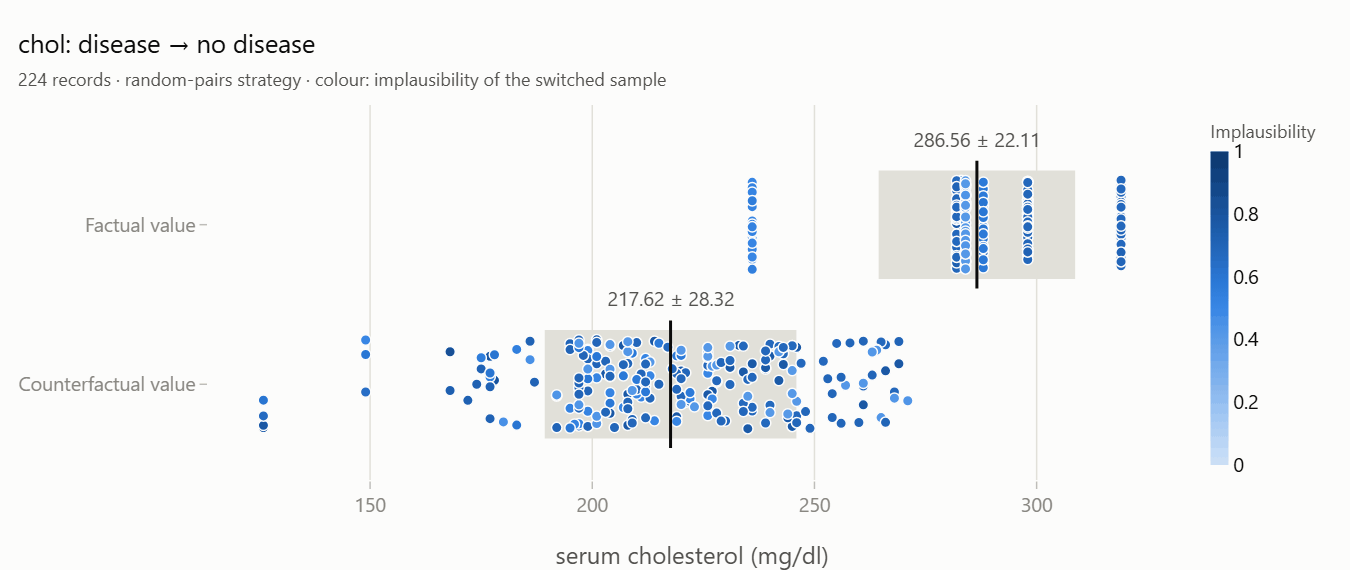

In [11]:
figure = viz.plot_rule(rules, interval)
figure.update_xaxes(title=MEANING[interval.feature])
viz.show(figure)

Each dot is one record: the factual patient's value on the upper row, the value after the switch on the lower row,
coloured by the implausibility of the switched patient. The shaded bands are the two intervals of the rule, mean ±
standard deviation, and the black lines their means. The upper row has few distinct values because the records come
from seven patients with disease, each switched to the cholesterol of many patients without: lowering it from about
290 to about 220 mg/dl, with every other measurement unchanged, is enough for the model to predict *no disease*. The
two intervals do not overlap, but single values do (one factual patient has 236 mg/dl, and some switched values are
higher): the rule describes a shift of the distribution, not a threshold.

## 6. How good are the rules?

The paper scores a set of rules with three metrics, computed here on the training patients:

- **fidelity**: for each patient, RaMiCo chains the conditions of the 7 nearest records that start from its predicted
  class and applies them together; fidelity is the share of patients whose prediction changes. Higher is better.
- **incomprehensibility**: the average number of conditions in those chains. Lower is better.
- **implausibility**: the average implausibility of the rules. Lower is better.

`metrics.evaluate` computes the three at once and gives each by name, `scores.fidelity`,
`scores.incomprehensibility` and `scores.implausibility`; `metrics.fidelity(model, rules, X)` and its siblings
compute one alone.

In [12]:
scores = metrics.evaluate(model, rules, X_train)
summary = pd.DataFrame(
    {
        "metric": ["Fidelity", "Incomprehensibility", "Implausibility"],
        "value": [
            f"{scores.fidelity:.1f}%",
            f"{scores.incomprehensibility:.2f}",
            f"{scores.implausibility:.3f}",
        ],
        "better": ["higher", "lower", "lower"],
        "meaning": [
            "patients whose prediction changes under the conditions of their nearest rules",
            "conditions per rule chain",
            "anomaly score of the switched patients, from 0 (typical) to 1",
        ],
    }
)
(
    GT(summary, rowname_col="metric")
    .tab_header(
        "How good are the rules?", f"{len(rules)} rules on {len(X_train)} training patients · 7 records per chain"
    )
    .cols_label(value="Value", better="Better", meaning="Meaning")
    .cols_align("right", columns="value")
)

GT(_tbl_data=                metric  value  better  \
0             Fidelity  63.7%  higher   
1  Incomprehensibility   2.06   lower   
2       Implausibility  0.548   lower   

                                             meaning  
0  patients whose prediction changes under the co...  
1                          conditions per rule chain  
2  anomaly score of the switched patients, from 0...  , _body=<great_tables._gt_data.Body object at 0x000002AF0CFEC350>, _boxhead=Boxhead([ColInfo(var='metric', type=<ColInfoTypeEnum.stub: 2>, column_label='metric', column_align='left', column_width=None, stub_level=0), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='Value', column_align='right', column_width=None, stub_level=None), ColInfo(var='better', type=<ColInfoTypeEnum.default: 1>, column_label='Better', column_align='left', column_width=None, stub_level=None), ColInfo(var='meaning', type=<ColInfoTypeEnum.default: 1>, column_label='Meaning', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000002AF0D9C3B60>, _spanners=Spanners([]), _heading=Heading(title='How good are the rules?', subtitle='72 rules on 237 training patients · 7 records per chain', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000002AF0CFEDC40>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000002AF0CFEE8A0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000002AF0CFEE990>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, 

## 7. Save the results and use them later

Extracting the rules took about a minute here, and takes hours on large data such as Adult. `rules.save`
writes everything to one file: the rules, the records behind them, how they were obtained (strategy, *s*, *k*,
seed, classes) and, with `scores=`, the metrics. The file is plain JSON whose tables have the columns of
`rules.to_frame()` and `rules.records`; a name ending in `.json.gz` compresses it about thirty times.

In [13]:
from pathlib import Path

from ramico import RuleSet

path = Path("cache") / "01_heart_rules.json"  # the folder where the tutorials keep their results
path.parent.mkdir(exist_ok=True)
rules.save(path, scores=scores)
print(f"{path.as_posix()}: {path.stat().st_size / 1e6:.1f} MB")

cache/01_heart_rules.json: 3.6 MB


`RuleSet.load` reads the file back, in this session or in a new one, without the model: no fit and no scoring.
The loaded rules work as the original ones, with the metrics in `.scores`:

In [14]:
saved = RuleSet.load(path)  # in a new session, this line is all it takes
print(saved)
print(
    f"fidelity {saved.scores.fidelity:.1f}% · incomprehensibility {saved.scores.incomprehensibility:.2f}"
    f" · implausibility {saved.scores.implausibility:.3f}"
)
print("same rules and records:", saved.to_frame().equals(rules.to_frame()) and saved.records.equals(rules.records))
saved.filter(from_class=1, to_class=0, feature="chol")[0]

RuleSet(strategy='ensemble', rules=72, records=21986, classes=[1, 0])
fidelity 63.7% · incomprehensibility 2.06 · implausibility 0.548
same rules and records: True


Rule(strategy='random-pairs', from_class=1, to_class=0, feature='chol', aggregation='mean', from_value=286.56, from_std=22.11, from_confidence=nan, to_value=217.62, to_std=28.32, to_confidence=nan, n_records=224, support=1.02, implausibility=0.635, implausibility_std=0.118, from_name='disease', to_name='no disease')

## 8. Make it yours

- **Another strategy**: `RaMiCo(model, strategy="boundary")`, or `"prototype"` and `"random"`; tutorial
  [02](02_mining_strategies.ipynb) compares them.
- **More or fewer samples**: `n_factuals` (*s*) and `n_counterfactuals` (*k*) trade run time for coverage.
- **The paper's MLP**: `MODEL = "mlp"` in the first code cell explains the multilayer perceptron instead.
- **Any model**: scikit-learn estimators and pipelines, XGBoost, or a plain function returning one label per row.
- **Your data**: name integer-coded categories with `categorical_features=[...]`; give arrays their column names with
  `feature_names=[...]`.
- **The raw material**: `rules.to_frame()` has one row per rule and `rules.records` one row per switch, as plain
  DataFrames:

In [15]:
text = ["strategy", "feature", "from_value", "to_value"]
(
    rules.to_frame()[["strategy", "from_class", "to_class", *text[1:], "n_records", "support"]]
    .head(8)
    .style.hide(axis="index")
    .format(lambda v: f"{v:g}" if isinstance(v, float) else v, subset=["from_value", "to_value"])
    .format("{:.2f}%", subset="support")
    .bar(subset="support", color=viz.theme.SEQUENTIAL[2], vmin=0, height=70)
    .set_properties(subset=text, **{"text-align": "left"})
    .set_table_styles({column: [{"selector": "th", "props": "text-align: left"}] for column in text})
)

strategy,from_class,to_class,feature,from_value,to_value,n_records,support
prototype,1,0,thal,reversible defect,normal,1067,4.85%
prototype,1,0,cp,asymptomatic,non-anginal pain,942,4.28%
random-pairs,1,0,thal,reversible defect,normal,880,4.00%
random-pairs,1,0,cp,asymptomatic,non-anginal pain,868,3.95%
nearest-boundary,1,0,thal,reversible defect,normal,746,3.39%
nearest-boundary,1,0,ca,1.49,0,741,3.37%
nearest-boundary,1,0,cp,asymptomatic,non-anginal pain,717,3.26%
prototype,1,0,ca,1.38,0,672,3.06%
